# 05 · The Barren Plateau

**The honest crux: why you cannot just scale up.** Sample random parameters for a random deep circuit and measure the variance of a cost-gradient component. As the circuit gets wider, that variance **collapses exponentially** toward zero — until the gradient is numerically indistinguishable from zero everywhere and the optimizer has no direction to follow.

This is a *proven property of the landscape*, not a bug. It is the central, measured reason deep variational quantum models do not simply train their way to an advantage.

In [ ]:
import sys, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Resolve the repo root whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

FIG = ROOT / "outputs" / "figures"
DATA = ROOT / "outputs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)


def _ser(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, complex):
        return {"re": float(o.real), "im": float(o.imag)}
    raise TypeError(f"not JSON-serializable: {type(o)!r}")


def save_json(name, obj):
    """Save textual/numerical results to outputs/data/<name>."""
    path = DATA / name
    path.write_text(json.dumps(obj, indent=2, default=_ser))
    print("saved", path.relative_to(ROOT))


def save_fig(fig, name):
    """Save a figure as PNG to outputs/figures/<name>."""
    path = FIG / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


def amp_list(state):
    """A statevector as a JSON-friendly list of {re, im} amplitudes."""
    return [{"re": float(a.real), "im": float(a.imag)} for a in np.asarray(state)]


plt.rcParams.update({"figure.figsize": (7.0, 4.0), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)
print("repo root:", ROOT)


repo root: /workspaces/quantum_ml_101


## Gradient variance vs qubit count

For each qubit count we draw many random parameter sets, take the exact parameter-shift derivative of one angle (for a global $Z^{\otimes n}$ cost), and compute the variance of that gradient across the landscape.

In [2]:
from src.analysis.barren import scan_qubits

qubits = [2, 3, 4, 5, 6, 7, 8]
variances = scan_qubits(qubits, n_layers=10, n_samples=150, seed=0)
vals = np.array([variances[n] for n in qubits])
for n in qubits:
    print(f'{n} qubits:  Var(dC/dtheta) = {variances[n]:.3e}')

# Fit the exponential: log(var) ~ slope * n + b.
slope, intercept = np.polyfit(qubits, np.log(vals), 1)
per_qubit = float(np.exp(slope))
print(f'\nvariance multiplied by ~{per_qubit:.2f} per added qubit (exponential decay)')
print(f'collapse factor {qubits[0]}q -> {qubits[-1]}q: {vals[0] / vals[-1]:.0f}x')

2 qubits:  Var(dC/dtheta) = 2.250e-01
3 qubits:  Var(dC/dtheta) = 1.044e-01
4 qubits:  Var(dC/dtheta) = 5.735e-02
5 qubits:  Var(dC/dtheta) = 2.838e-02
6 qubits:  Var(dC/dtheta) = 1.872e-02
7 qubits:  Var(dC/dtheta) = 7.967e-03
8 qubits:  Var(dC/dtheta) = 4.133e-03

variance multiplied by ~0.52 per added qubit (exponential decay)
collapse factor 2q -> 8q: 54x


saved outputs/figures/05_barren_plateau.png
saved outputs/data/05_variances_vs_qubits.json


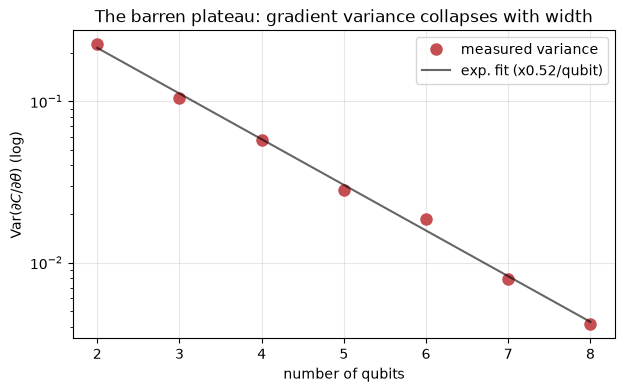

In [3]:
fit = np.exp(intercept + slope * np.array(qubits))
fig, ax = plt.subplots()
ax.semilogy(qubits, vals, 'o', color='#c44e52', ms=8, label='measured variance')
ax.semilogy(qubits, fit, '-', color='k', alpha=0.6, label=f'exp. fit (x{per_qubit:.2f}/qubit)')
ax.set_xlabel('number of qubits')
ax.set_ylabel(r'Var$(\partial C / \partial \theta)$ (log)')
ax.set_title('The barren plateau: gradient variance collapses with width')
ax.legend()
save_fig(fig, '05_barren_plateau.png')

save_json('05_variances_vs_qubits.json', {
    'qubits': qubits,
    'variance': vals.tolist(),
    'decay_per_qubit': per_qubit,
    'collapse_factor': float(vals[0] / vals[-1]),
})

## Depth drives it too

At a fixed width, adding depth also flattens the landscape as the circuit approaches a random unitary. Here is the variance vs number of layers at 6 qubits.

depth  2:  Var = 1.149e-02
depth  4:  Var = 1.587e-02
depth  6:  Var = 1.347e-02
depth  8:  Var = 2.081e-02
depth 12:  Var = 2.128e-02
depth 16:  Var = 1.526e-02
depth 20:  Var = 2.081e-02
saved outputs/figures/05_barren_vs_depth.png
saved outputs/data/05_variances_vs_depth.json


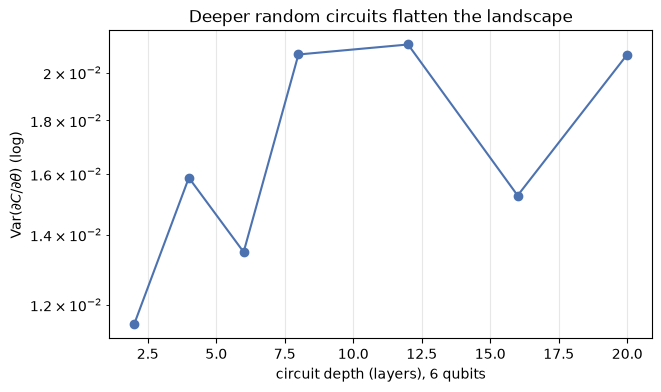

In [4]:
from src.analysis.barren import gradient_variance

depths = [2, 4, 6, 8, 12, 16, 20]
var_depth = np.array([gradient_variance(6, d, n_samples=150, seed=0) for d in depths])
for d, v in zip(depths, var_depth):
    print(f'depth {d:>2}:  Var = {v:.3e}')

fig, ax = plt.subplots()
ax.semilogy(depths, var_depth, 'o-', color='#4c72b0')
ax.set_xlabel('circuit depth (layers), 6 qubits')
ax.set_ylabel(r'Var$(\partial C / \partial \theta)$ (log)')
ax.set_title('Deeper random circuits flatten the landscape')
save_fig(fig, '05_barren_vs_depth.png')

save_json('05_variances_vs_depth.json', {
    'depths': depths,
    'variance_at_6_qubits': var_depth.tolist(),
})

## It is the landscape, not a bug — and the mitigations

The collapse is a theorem about random deep circuits (McClean et al. 2018), not a numerical glitch. The known partial mitigations keep the gradient alive by *not* being a random deep circuit:

- **Shallow circuits** — stay far from a 2-design.
- **Local cost functions** — measure few qubits, not a global observable.
- **Structured / problem-informed ansatze** — restrict the parameter space.
- **Identity-block initialization** — start where the gradient is not yet flat.

None of these is a free pass to scale; they are why you must design the circuit, not just widen it.

In [5]:
save_json('05_summary.json', {
    'phenomenon': 'barren plateau',
    'measured': f'gradient variance decays ~{per_qubit:.2f}x per qubit (exponential)',
    'is_a_bug': False,
    'reference': 'McClean et al., Nature Communications (2018)',
    'mitigations': ['shallow circuits', 'local cost functions', 'structured ansatze', 'identity-block init'],
})
print('The deeper and wider the circuit, the flatter the plain the optimizer stands on.')

saved outputs/data/05_summary.json
The deeper and wider the circuit, the flatter the plain the optimizer stands on.


## Takeaways

- Gradient variance collapses exponentially with qubit count — measured, not claimed.
- Depth makes it worse; the effect is a property of the landscape.
- You cannot scale a random deep VQC to force an advantage; you must design it.

Next: **06 — Decision Framework**, the honest guide to what is real and what is hype.